In [210]:
import torch
import timm
import torch.nn.functional as F
from torchvision.transforms.functional import gaussian_blur
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

In [211]:
from paths import path_to_tiles_tensor
from paths import path_to_tiles_metadata

In [214]:
tiles = torch.load(path_to_tiles_tensor)
# extract batch
batch = tiles[0:10, :, :, :]

## First channel: Normalise only (same across)

In [213]:
batch_size = 50
q = torch.tensor([0.05, 0.95])

low_quantile_per_tile = []
high_quantile_per_tile = []

for i in range(0, tiles.shape[0], batch_size):
    analysis_batch = tiles[i:i + batch_size]                   
    flat = analysis_batch.reshape(analysis_batch.shape[0], analysis_batch.shape[1], -1).float()
    qs = torch.quantile(flat, q, dim = -1)         
    low_quantile_per_tile.append(qs[0])              
    high_quantile_per_tile.append(qs[1])

low_quantile_per_tile = torch.cat(low_quantile_per_tile)
high_quantile_per_tile = torch.cat(high_quantile_per_tile)

lower_absolute = torch.min(low_quantile_per_tile)
upper_absolute = torch.max(high_quantile_per_tile)

print(lower_absolute.item())
print(upper_absolute.item())

90.87999725341797
200.5922393798828


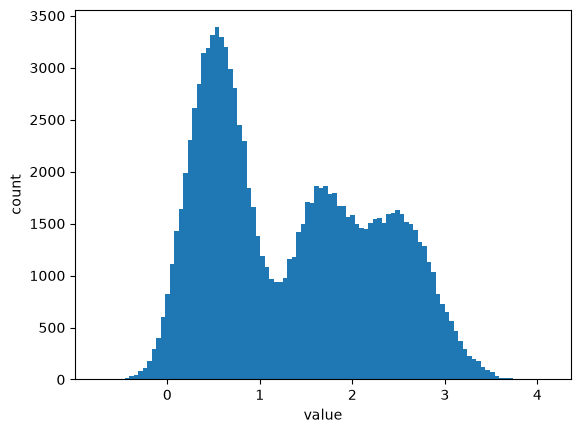

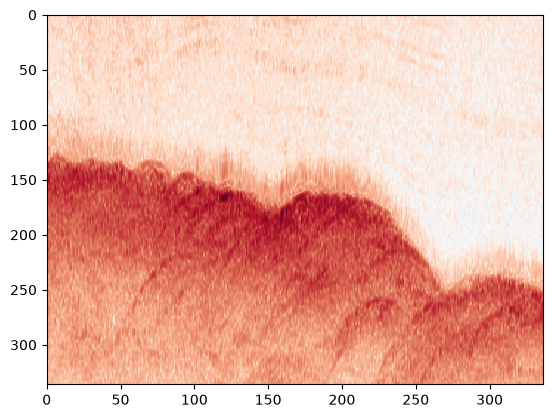

In [215]:
def normalise(batch_of_tiles, low = 100.0, high = 180.00):
    ### Normalise all tiles with same values to retain absolute meaning
    # e.g. 145 becomes 0 (center)
    center = (low + high) / 2
    # e.g. 90 becomes -3 and 200 becomes 3      
    half_range = (high - low) / 2 

    batch_of_tiles_norm = (batch_of_tiles - center) / half_range * 3

    return batch_of_tiles_norm

batch_of_tiles_norm = normalise(batch)

# Look at distribution
i = 7
x = batch_of_tiles_norm[i].flatten().detach().cpu().numpy()
plt.hist(x, bins = 100)
plt.xlabel("value")
plt.ylabel("count")
plt.show()

plt.pcolormesh(batch_of_tiles_norm[i, 0], cmap = "RdBu_r", vmin = -4, vmax = 4)
plt.gca().invert_yaxis()
plt.show()

## Second channel: Normalise against attenuation proxy

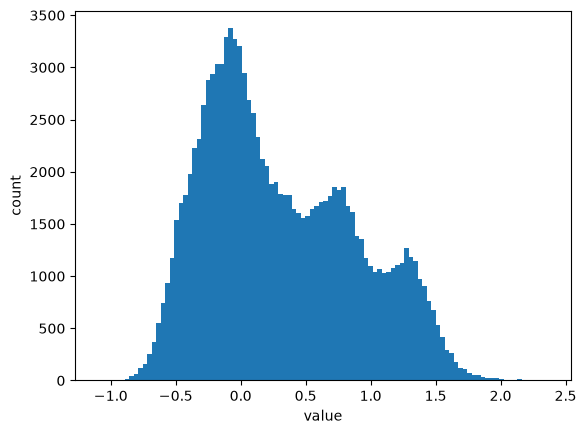

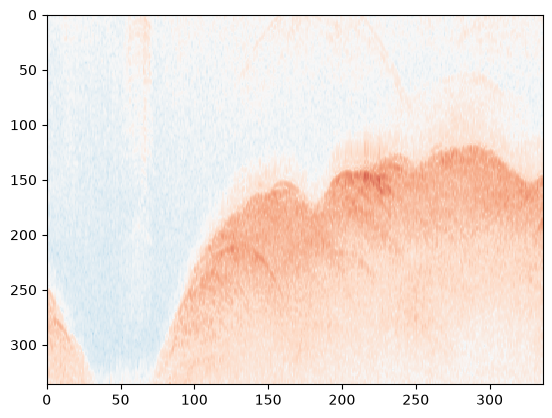

In [216]:
def normalise_wrt_near_basal_power(batch_of_tiles, window_width = 40, full_window_height = 100, scalar = 0.05):
    ### This function expresses echo relative to the mean near basal ice echo (proxy for attenuation correction)
    # input shape: (N, 1, H, W)
    # output shape: (N, 1, H, W)
    H = batch_of_tiles.shape[-2]
    W = batch_of_tiles.shape[-1]
    half_W = int(W / 2)
    half_window_width = int(window_width / 2)
    # mean over C1 , H and W but keepdim for subtraction
    batch_near_basal_mean = batch_of_tiles[:, :, :full_window_height, (half_W - half_window_width) : (half_W + half_window_width)].mean(dim = (1, 2, 3), keepdim = True)

    # subtract this to make it 0
    batch_of_tiles_shifted = batch_of_tiles - batch_near_basal_mean

    # scalar (fixed)
    batch_of_tiles_shifted_scaled = batch_of_tiles_shifted * scalar

    return batch_of_tiles_shifted_scaled

batch_of_tiles_shifted_scaled = normalise_wrt_near_basal_power(batch)

# Look at distribution
i = 2
x = batch_of_tiles_shifted_scaled[i].flatten().detach().cpu().numpy()
plt.hist(x, bins = 100)
plt.xlabel("value")
plt.ylabel("count")
plt.show()

plt.pcolormesh(batch_of_tiles_shifted_scaled[i, 0], cmap = "RdBu_r", vmin = -4, vmax = 4)
plt.gca().invert_yaxis()
plt.show()

## Third channel: Extract contours

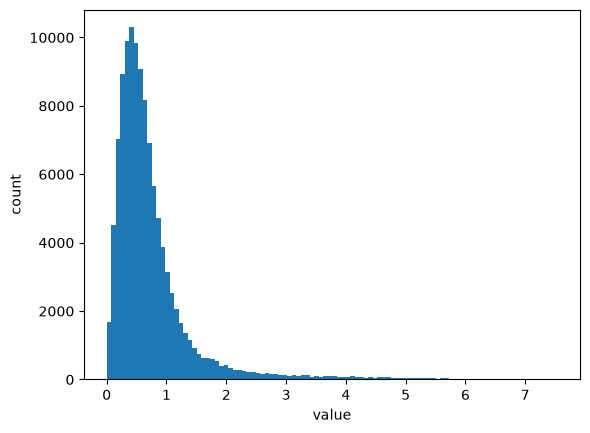

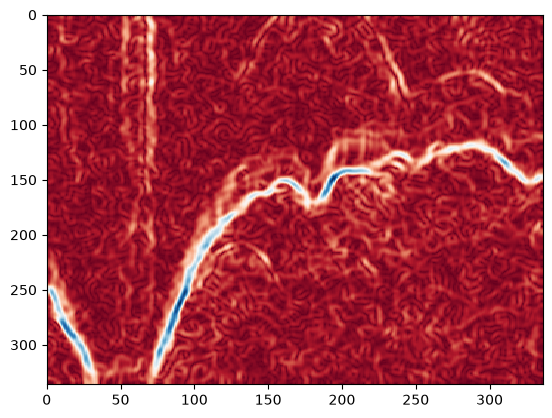

In [217]:
_KX = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]])

def apply_sobel(batch_of_tiles, scalar = 0.2):
    # input shape: (N, 1, H, W)
    # output shape: (N, 1, H, W)
    # first smooth out noise and speckle
    batch_of_tiles_smoothed = gaussian_blur(batch_of_tiles, kernel_size = 9, sigma = 2.0)
    # horizontal and vertical sobel 3 x 3 kernel i.e. window to detect horizontal and vertical change
    # kernels: torch.Size([2, 1, 3, 3])
    kernels = torch.stack([_KX, _KX.T])[:, None].to(batch_of_tiles.device, batch_of_tiles.dtype)   
    # borders             
    g = F.conv2d(F.pad(batch_of_tiles_smoothed, (1, 1, 1, 1), mode = 'reflect'), kernels)
    # collapeses both sobels into one and keep only positive values.
    g = g.norm(dim = 1, keepdim = True) 
    # scale to reduce std
    g = g * scalar
    return g

g = apply_sobel(batch)

i = 2
x = g[i].flatten().detach().cpu().numpy()
plt.hist(x, bins = 100)
plt.xlabel("value")
plt.ylabel("count")
plt.show()

plt.pcolormesh(g[i, 0], cmap = "RdBu")
# plt.pcolormesh(g[i, 0], cmap = "RdBu", vmin = -3, vmax = 3)
plt.gca().invert_yaxis()
plt.show()

# Combine

In [218]:
def channelise(batch_of_tiles):
    # input shape: (N, 1, H, W)
    # output shape: (N, 3, H, W)
    batch_norm = normalise(batch_of_tiles)
    batch_norm_rel = normalise_wrt_near_basal_power(batch_of_tiles)
    batch_sobel = apply_sobel(batch_of_tiles)

    # cat along dim 1 
    batch_3C = torch.cat([batch_norm, batch_norm_rel, batch_sobel], dim = 1)
    return batch_3C

print(batch.shape)
batchy_3D = channelise(batch)
print(batchy_3D.shape)

torch.Size([10, 1, 336, 336])
torch.Size([10, 3, 336, 336])


# Train